# 07: An upper bound on the heat-only channel

Notebooks 03–06 closed every route except one: fusion whose ~24 MeV goes **directly into lattice heat**, with no neutrons, protons, tritons or gammas. That's the channel low-energy nuclear reaction (LENR) theories rely on (Hagelstein and others), and the only one consistent with reports of heat plus ⁴He without radiation. Notebook 01 flagged it as a "10⁹ timescale problem". This notebook turns that into numbers.

**Logic.** When two deuterons fuse they form excited ⁴He (23.85 MeV above the ground state). It then decays through competing channels with widths Γ (rates Γ/ħ):

* **strong breakup** (p+t, n+³He): Γ_strong, MeV-scale;
* **gamma emission** (⁴He + γ): Γ_γ ≈ 10⁻⁷ Γ_strong (measured);
* **a hypothetical lattice channel:** Γ_lat.

To make heat dominate with neutrons suppressed by a factor $s_n$, we need $\Gamma_{lat} \gtrsim \Gamma_{strong}/s_n$. We compute that requirement, then bound Γ_lat for every known way a nucleus can hand energy to its surroundings.

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
HBAR = 6.582119569e-16      # eV s
dE = 23.85e6                # eV, d+d -> 4He excitation
G_STRONG = [0.5e6, 6.2e6]   # eV: MeV-scale widths of 4He levels near threshold (e.g. 1- at 23.64 MeV, width 6.2 MeV)
GAMMA_BR = 1.06e-7          # Gamma_gamma / Gamma_p at 20 keV (Zhou et al. 2006)
phonon = 0.037              # eV, PdD optical phonon
for G in G_STRONG:
    print(f"Gamma_strong = {G/1e6:.1f} MeV -> lifetime {HBAR/G:.1e} s")
print(f"phonon period {4.135667e-15/phonon:.1e} s;  phonons to absorb 23.85 MeV: {dE/phonon:.2e}")

Gamma_strong = 0.5 MeV -> lifetime 1.3e-21 s
Gamma_strong = 6.2 MeV -> lifetime 1.1e-22 s
phonon period 1.1e-13 s;  phonons to absorb 23.85 MeV: 6.45e+08


## 1. How strong must the lattice channel be?

Heat-plus-helium claims cite ~10¹¹–10¹² ⁴He per second per watt, with neutron emission at or below background. With ordinary branching, 1 W of d+d would give ~10¹² neutrons/s. A cell with neutron emission below ~1 n/s therefore implies $s_n \lesssim 10^{-12}$ (an **assumed** illustrative detection level; the scan covers 10⁻³ to 10⁻¹⁴).

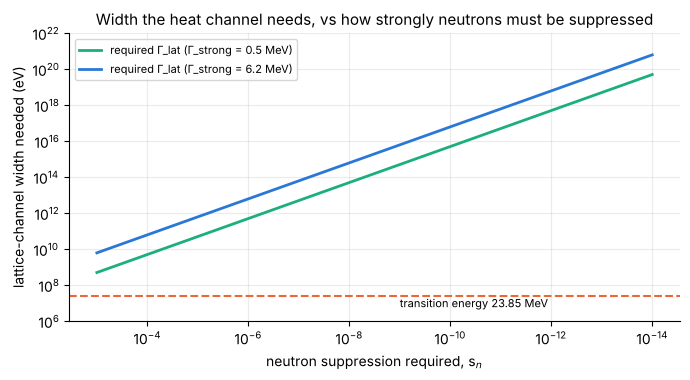

s_n = 1e-03: Gamma_lat >= 5.0e+08 – 6.2e+09 eV  =  2.1e+01 – 2.6e+02 x the transition energy
s_n = 1e-06: Gamma_lat >= 5.0e+11 – 6.2e+12 eV  =  2.1e+04 – 2.6e+05 x the transition energy
s_n = 1e-09: Gamma_lat >= 5.0e+14 – 6.2e+15 eV  =  2.1e+07 – 2.6e+08 x the transition energy
s_n = 1e-12: Gamma_lat >= 5.0e+17 – 6.2e+18 eV  =  2.1e+10 – 2.6e+11 x the transition energy


In [2]:
s_n = np.logspace(-14, -3, 200)
fig, ax = plt.subplots(figsize=(7, 3.9))
for G, col in zip(G_STRONG, [AQUA, BLUE]):
    ax.loglog(s_n, G/s_n, color=col, lw=2, label=f"required Γ_lat (Γ_strong = {G/1e6:.1f} MeV)")
ax.axhline(dE, color=ORANGE, ls="--", lw=1.5); ax.text(1e-9, dE*0.25, "transition energy 23.85 MeV", fontsize=8)
ax.set_xlabel("neutron suppression required, s$_n$"); ax.set_ylabel("lattice-channel width needed (eV)")
ax.set_ylim(1e6, 1e22); ax.invert_xaxis(); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Width the heat channel needs, vs how strongly neutrons must be suppressed")
plt.tight_layout(); plt.savefig("../figures/07_required_width.png", dpi=130); plt.show()
for s in [1e-3, 1e-6, 1e-9, 1e-12]:
    lo, hi = G_STRONG[0]/s, G_STRONG[1]/s
    print(f"s_n = {s:.0e}: Gamma_lat >= {lo:.1e} – {hi:.1e} eV  =  {lo/dE:.1e} – {hi/dE:.1e} x the transition energy")

**Result:** even a modest 1000× neutron suppression needs a lattice width **~20–260× larger than the transition energy itself**, and at $s_n = 10^{-12}$ about 10¹⁰–10¹¹× larger. A "state" whose width exceeds its excitation energy decays faster than ħ/ΔE ≈ 3×10⁻²³ s. At that point there is no excited ⁴He nucleus for the lattice to couple to. **Heat-only at these suppression levels is incompatible with the reaction going through an excited ⁴He compound nucleus at all.** Sections 2–4 bound Γ_lat for the mechanisms that do go through that state.

## 2. Electromagnetic channels: gamma, internal conversion, pair creation

In [3]:
alpha = 1/137.036; me = 0.511e6
G_gamma = [GAMMA_BR*G for G in G_STRONG]
# order-of-magnitude internal-conversion coefficient for a Z=2 nucleus at 23.85 MeV (E1-like scaling):
alpha_IC = 2**3*alpha**4*(2*me/dE)**3.5
alpha_pair = 1e-2       # internal pair creation per gamma at ~20 MeV: generous order of magnitude
print(f"Gamma_gamma ~ {G_gamma[0]:.1e} – {G_gamma[1]:.1e} eV")
print(f"internal conversion coefficient (Z=2, 24 MeV) ~ {alpha_IC:.0e}; even x10^6 for a dense metal electron gas: {alpha_IC*1e6:.0e}")
print(f"internal pair creation per gamma ~ {alpha_pair:.0e} (and the pairs annihilate into 511 keV gammas, which are detectable)")
print(f"=> total EM non-radiative width <~ {G_gamma[1]*(alpha_IC*1e6 + alpha_pair):.1e} eV, vs required >= {G_STRONG[0]/1e-3:.1e} eV even at s_n = 1e-3")

Gamma_gamma ~ 5.3e-02 – 6.6e-01 eV
internal conversion coefficient (Z=2, 24 MeV) ~ 4e-13; even x10^6 for a dense metal electron gas: 4e-07
internal pair creation per gamma ~ 1e-02 (and the pairs annihilate into 511 keV gammas, which are detectable)
=> total EM non-radiative width <~ 6.6e-03 eV, vs required >= 5.0e+08 eV even at s_n = 1e-3


**Result:** the electromagnetic route to electrons (internal conversion) is ~10⁻¹³ per gamma for a Z=2 nucleus at 24 MeV. Even a million-fold enhancement from a metal's electron gas leaves it hopeless, and internal pair creation emits annihilation gammas. **The total EM non-radiative width (≲10⁻² eV) falls short of the weakest requirement (5×10⁸ eV at s_n = 10⁻³) by ~11 orders of magnitude, and by ~20 at s_n = 10⁻¹².** (The coefficients are scaling estimates, flagged as order-of-magnitude.)

## 3. Direct multi-phonon emission: the energy-gap law

The standard theory of non-radiative transitions in solids (the Englman–Jortner energy-gap law) gives the rate for handing an energy ΔE to *n* = ΔE/ħω phonons, with coupling set by the Huang–Rhys factor *S* (lattice relaxation energy / ħω):

$$W \approx \omega\,\exp\!\Big[-n\Big(\ln\frac{n}{S}-1\Big) - S\Big]$$

For a nuclear transition, the lattice only "notices" changes in the nucleus's charge distribution and mass. Those give relaxation energies of μeV–meV (isomer/isotope-shift scale). We scan generously, up to 24 keV (the Pd K-shell binding energy) and beyond.

In [4]:
n = dE/phonon; omega = phonon/HBAR
def log10_W(E_relax):
    S = E_relax/phonon
    return np.log10(omega) + (-n*(np.log(n/S) - 1) - S)/np.log(10)
need_rate = np.log10(G_STRONG[0]/HBAR/1e-3)       # weakest requirement: s_n = 1e-3, narrow level
print(f"n = {n:.2e} phonons; required rate >= 10^{need_rate:.1f} /s (s_n = 1e-3)")
for Er, lab in [(1e-6, "1 ueV (isomer-shift scale)"), (1e-3, "1 meV"), (10, "10 eV (chemical bond)"),
                (24e3, "24 keV (Pd K-shell)"), (1e6, "1 MeV (absurd)"), (dE/np.e, "dE/e (gap law turnover)")]:
    lw = log10_W(Er)
    print(f"   E_relax = {lab:28s}: rate 10^({lw:.3e})")

n = 6.45e+08 phonons; required rate >= 10^23.9 /s (s_n = 1e-3)
   E_relax = 1 ueV (isomer-shift scale)  : rate 10^(-8.343e+09)
   E_relax = 1 meV                       : rate 10^(-6.409e+09)
   E_relax = 10 eV (chemical bond)       : rate 10^(-3.831e+09)
   E_relax = 24 keV (Pd K-shell)         : rate 10^(-1.652e+09)
   E_relax = 1 MeV (absurd)              : rate 10^(-6.197e+08)
   E_relax = dE/e (gap law turnover)     : rate 10^(-1.030e+08)


**Result:** with any physically plausible coupling (μeV–10 eV), the multi-phonon rate is around **10^(−4×10⁹ to −8×10⁹) s⁻¹**. Even with absurd MeV-scale relaxation energies it stays below 10^(−10⁸): at that point the Debye–Waller-type factor e^(−S) takes over. **Direct multi-phonon conversion is excluded by roughly a billion orders of magnitude.**

## 4. Coherent many-nucleus coupling (the Hagelstein-type loophole)

If one excitation couples coherently to *N* sites, the collective coupling grows as √N·g (single-site coupling g), and each site need only take ΔE/N. Two requirements:

* **Speed:** √N·g ≳ Γ_lat,needed, so the transfer beats the strong breakup.
* **Capacity:** ΔE/N ≲ the energy one site can absorb (~eV, else that site's atom is ejected or the lattice is damaged).

In [5]:
rows = []
for g, glab in [(1e-3, "1 meV"), (10, "10 eV"), (24e3, "24 keV (absurdly generous)")]:
    for s in [1e-3, 1e-12]:
        need = G_STRONG[0]/s
        N_speed = (need/g)**2; N_cap = dE/1.0
        rows.append((glab, s, N_speed, N_cap))
        print(f"g = {glab:26s} s_n = {s:.0e}:  N >= {N_speed:.1e} for speed,  N >= {N_cap:.1e} for capacity")
print("\nfor scale: coherent phonon domains ~1e2–1e3 sites (notebook 01); Pd atoms in 1 cm^3 = 6.8e22; atoms in Earth ~1e50")

g = 1 meV                      s_n = 1e-03:  N >= 2.5e+23 for speed,  N >= 2.4e+07 for capacity
g = 1 meV                      s_n = 1e-12:  N >= 2.5e+41 for speed,  N >= 2.4e+07 for capacity
g = 10 eV                      s_n = 1e-03:  N >= 2.5e+15 for speed,  N >= 2.4e+07 for capacity
g = 10 eV                      s_n = 1e-12:  N >= 2.5e+33 for speed,  N >= 2.4e+07 for capacity
g = 24 keV (absurdly generous) s_n = 1e-03:  N >= 4.3e+08 for speed,  N >= 2.4e+07 for capacity
g = 24 keV (absurdly generous) s_n = 1e-12:  N >= 4.3e+26 for speed,  N >= 2.4e+07 for capacity

for scale: coherent phonon domains ~1e2–1e3 sites (notebook 01); Pd atoms in 1 cm^3 = 6.8e22; atoms in Earth ~1e50


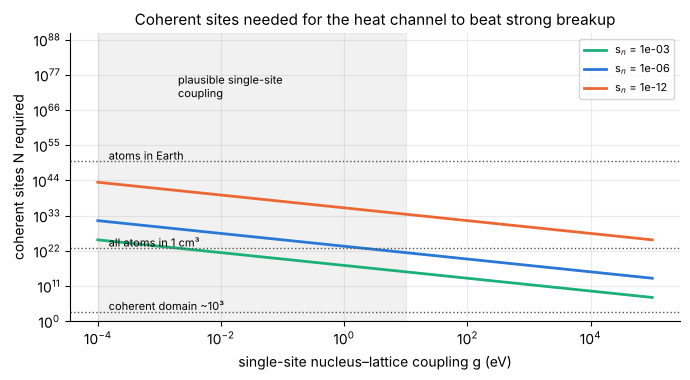

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.9))
gs = np.logspace(-4, 5, 200)
for s, col in [(1e-3, AQUA), (1e-6, BLUE), (1e-12, ORANGE)]:
    ax.loglog(gs, (G_STRONG[0]/s/gs)**2, color=col, lw=2, label=f"s$_n$ = {s:.0e}")
for y, lab in [(1e3, "coherent domain ~10³"), (6.8e22, "all atoms in 1 cm³"), (1e50, "atoms in Earth")]:
    ax.axhline(y, color=MUTED, ls=":", lw=1); ax.text(1.5e-4, y*3, lab, fontsize=8)
ax.axvspan(1e-4, 10, color=MUTED, alpha=.08); ax.text(2e-3, 1e70, "plausible single-site\ncoupling", fontsize=8)
ax.set_xlabel("single-site nucleus–lattice coupling g (eV)"); ax.set_ylabel("coherent sites N required")
ax.set_ylim(1, 1e90); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Coherent sites needed for the heat channel to beat strong breakup")
plt.tight_layout(); plt.savefig("../figures/07_coherent_N.png", dpi=130); plt.show()

**Result:** at the weakest suppression (s_n = 10⁻³) and a generous 10 eV single-site coupling, the speed requirement alone needs **~2.5×10¹⁵ coherently coupled nuclei**. At realistic suppression (10⁻¹²) it needs ~2.5×10³³. Coherent domains in a warm lattice hold ~10³. Even with an absurd 24 keV coupling, s_n = 10⁻¹² needs ~4×10²⁶ sites (about 70 kg of Pd).

**And a causality limit that no N can beat:** the transfer must finish within the compound-nucleus lifetime, ~10⁻²²–10⁻²¹ s. In that time light travels **0.3–3×10⁻¹³ m, i.e. 0.0003–0.003 Å**, far less than the 2.75 Å to the nearest neighbouring deuteron. No signal from the fusing pair can reach even one other lattice site before the excited ⁴He has broken up. Coherent sharing across sites would have to be set up *before* the fusion event, which means the energy transfer would have to begin before the nucleus exists.

## 5. Verdict

| Route for 24 MeV to become heat | Shortfall |
|---|---|
| Electromagnetic (internal conversion, pair creation) | ~11 (s_n = 10⁻³) to ~20 (s_n = 10⁻¹²) orders of magnitude; pair creation also emits detectable gammas |
| Direct multi-phonon (energy-gap law) | ~10⁹ orders of magnitude |
| Coherent many-nucleus coupling | needs ~10¹⁵–10³³ phase-locked nuclei vs ~10³ available, **and** is forbidden by causality: light covers < 0.003 Å in the compound-nucleus lifetime |
| Any route through an excited ⁴He state, at s_n ≤ 10⁻³ | the required width exceeds the transition energy |

**The heat-only loophole closes for any mechanism that forms an excited ⁴He nucleus.** What remains logically open is a process that **never forms the compound nucleus**: energy removed *while the deuterons are still approaching* (during tunneling), or physics outside the standard model. Both would need couplings of MeV per nucleus at femtometre-to-picometre separations. That's the same scale the earlier notebooks' Coulomb-barrier analysis already rules out for static screening.

**Combined with notebooks 03–06:** fusion at rest must either produce neutrons/gammas (excluded by the 1990 limits and testable further by E1) or go through a channel no known interaction can supply. **That's the full closure the series was aiming for**, within standard physics and the stated assumptions.

**Assumptions and status:** γ/p branching 1.06×10⁻⁷ (Zhou et al. 2006, abstract); ⁴He level widths MeV-scale (Tilley et al. 1992 evaluation, abstract-level); IC and pair coefficients are scaling estimates; the s_n = 10⁻¹² neutron-suppression level is illustrative; the energy-gap law is the weak-coupling (Englman–Jortner) form.